In [859]:
import torch
import torch.nn as nn
import torch.optim as optim
import snntorch as snn
from snntorch import spikegen
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from snntorch import surrogate, functional as SF
from scipy.stats import beta as beta_dist
import pickle
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
import scipy.io as sio

num_steps = 164
THRESHOLD = 0.3
SCALING_FACTOR = 0.1
SPIKE_GAIN = 1.3
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

num_folds = 5
lr=5e-4
eps=1e-8

kernel_tau = 75.0       # how fast does the kernel decay, the larger tau, the slower the decay
kernel_decay = torch.exp(torch.tensor(-1.0 / kernel_tau))


# ABP signal Analysis

dict_keys(['__header__', '__version__', '__globals__', 'patient', 'trial', 'SP', 'DP', 'signal', 'abp_signal', 'class_limits'])
abp_signal shape: (569, 164)
signal shape: (569, 625)
SP shape: (569, 1)
patient shape: (569, 1)
signal_fold keys: dict_keys(['__header__', '__version__', '__globals__', 'patient', 'trial', 'SP', 'DP', 'Gender', 'Age', 'Height_cm', 'Weight_kg', 'HeartCondition', 'Comments', 'signal', 'abp_signal'])
signal_mabp_fold keys: dict_keys(['__header__', '__version__', '__globals__', 'patient', 'trial', 'SP', 'DP', 'signal', 'abp_signal', 'class_limits'])

signal_fold signal shape: (671, 625)
signal_mabp_fold signal shape: (671, 625)


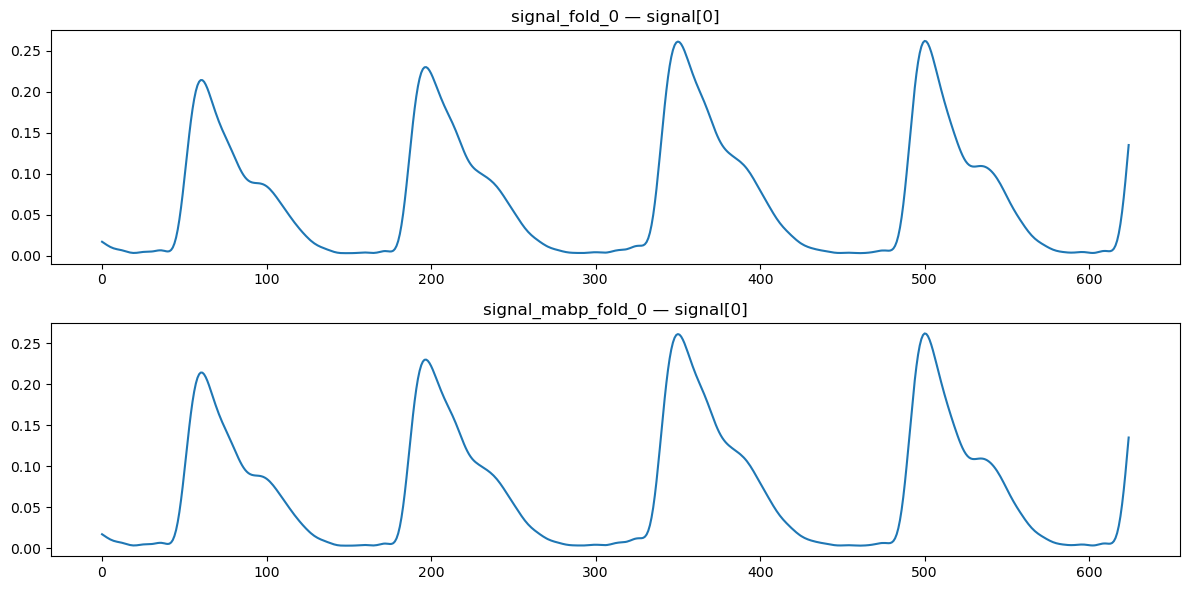

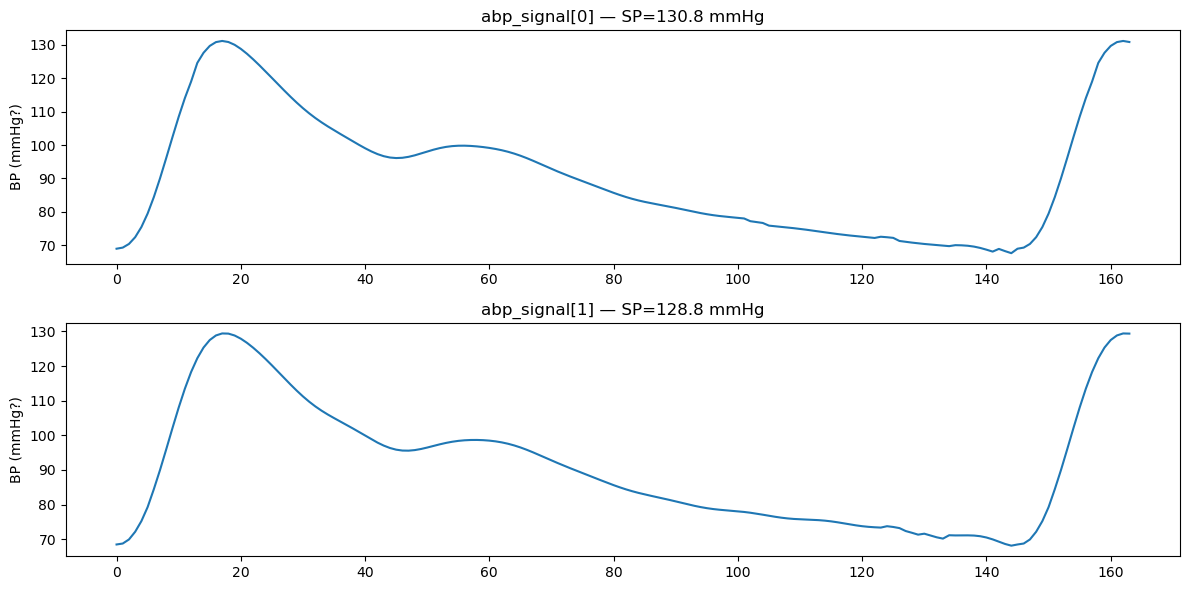

abp_signal range: 53.071495190252755 to 190.2287100981029
SP range: 94.88402161308166 to 191.0738151601068


In [860]:
import scipy.io as sio
mabp = sio.loadmat("bcg_dataset/signal_mabp_fold_4.mat")
print(mabp.keys())
print("abp_signal shape:", mabp['abp_signal'].shape)
print("signal shape:", mabp['signal'].shape)
print("SP shape:", mabp['SP'].shape)
print("patient shape:", mabp['patient'].shape)


# this confirms that the signal_fold_{}.mat signal are just the PPG signals which can also be found in the signal_mabp_fold_{}.mat file, together with the ABP signal
import scipy.io as sio
import matplotlib.pyplot as plt

sig = sio.loadmat("bcg_dataset/signal_fold_0.mat")
mabp = sio.loadmat("bcg_dataset/signal_mabp_fold_0.mat")

print("signal_fold keys:", sig.keys())
print("signal_mabp_fold keys:", mabp.keys())

print("\nsignal_fold signal shape:", sig['signal'].shape)
print("signal_mabp_fold signal shape:", mabp['signal'].shape)

# plot both for segment 0 to see if they look the same
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(sig['signal'][0])
axes[0].set_title('signal_fold_0 — signal[0]')
axes[1].plot(mabp['signal'][0])
axes[1].set_title('signal_mabp_fold_0 — signal[0]')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(mabp['abp_signal'][2])
axes[0].set_title(f"abp_signal[0] — SP={mabp['SP'][2,0]:.1f} mmHg")
axes[0].set_ylabel('BP (mmHg?)')

axes[1].plot(mabp['abp_signal'][3])
axes[1].set_title(f"abp_signal[1] — SP={mabp['SP'][3,0]:.1f} mmHg")
axes[1].set_ylabel('BP (mmHg?)')

plt.tight_layout()
plt.show()

print("abp_signal range:", mabp['abp_signal'].min(), "to", mabp['abp_signal'].max())
print("SP range:", mabp['SP'].min(), "to", mabp['SP'].max())

# Data Loading & Plots


In [861]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

In [862]:
def load_abp(fold_num):
    mat = sio.loadmat(f"bcg_dataset/signal_mabp_fold_{fold_num}.mat")
    return mat["abp_signal"]

#  this is important to see where the average abp signal starts. 
abp_all = np.concatenate([load_abp(i) for i in range(num_folds)])
mean_first_timestep = (abp_all[:, 0] / 100.0).mean()
print(mean_first_timestep)

0.6725183654085259


In [863]:
def plot_predictions(all_true, all_predictions, label, fold, samplingRange):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].scatter(all_true, all_predictions, alpha=0.4, s=10)
    axes[0].plot([all_true.min(), all_true.max()],
                 [all_true.min(), all_true.max()], 'r--', label='Perfect prediction')
    axes[0].set_xlabel(f"True {label}")
    axes[0].set_ylabel(f"Predicted {label}")
    axes[0].set_title(f"Fold {fold+1} - Predicted vs True {label}")
    axes[0].legend()

    axes[1].plot(all_true[:samplingRange], label=f'True {label}', alpha=0.8)
    axes[1].plot(all_predictions[:samplingRange], label=f'Predicted {label}', alpha=0.8)
    axes[1].set_xlabel("Sample")
    axes[1].set_ylabel(f"{label} (mmHg)")
    axes[1].set_title(f"Fold {fold+1} - First {samplingRange} Samples")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


In [864]:
# plot the signal we get after applying the kernel to the output spike train

def plot_signal(signal, spk_rec, abp_target, sample_idx=0):
    sig = signal[:,sample_idx,0].detach().cpu().numpy()
    spk = spk_rec[:,sample_idx,0].detach().cpu().numpy()
    target = (abp_target[sample_idx] / 100.0).detach().cpu().numpy()

    spike_times = np.where(spk > 0)[0]

    plt.close('all')
    plt.figure(figsize=(10, 4))

    for t in spike_times:
        plt.axvline(x=t, color='black', alpha=0.4, linewidth=0.8)

    plt.plot(sig, color='steelblue', label='kernel output signal', zorder=2)
    plt.plot(target, color='r', linestyle='--', label='true ABP waveform')
    plt.xlabel('timestep')
    plt.ylabel('BP (mmHg)')
    plt.title(f'Sample {sample_idx} — spike train + kernel output vs ABP target')
    plt.legend()
    plt.show()


'''
def plot_signal(signal, spk_rec, abp_target, sample_idx=0):
    sig = signal[:, sample_idx, 0].detach().cpu().numpy()
    target = (abp_target[sample_idx] / 100.0).detach().cpu().numpy()
    
    # spk_rec is now [164, 32, 1] averaged across neurons
    # multiply back by num_outputs to get mean firing rate per timestep
    avg_rate = spk_rec[:, sample_idx, 0].detach().cpu().numpy()

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]})

    axes[0].plot(sig, color='steelblue', label='kernel output signal', zorder=2)
    axes[0].plot(target, color='r', linestyle='--', label='true ABP waveform')
    axes[0].set_ylabel('BP (normalized)')
    axes[0].set_title(f'Sample {sample_idx} — kernel output vs ABP target')
    axes[0].legend()

    axes[1].bar(range(len(avg_rate)), avg_rate, color='black', alpha=0.6, width=1.0)
    axes[1].set_ylabel('avg spike rate')
    axes[1].set_xlabel('timestep')
    axes[1].set_ylim(0, 1)

    plt.tight_layout()
    plt.show()
'''

"\ndef plot_signal(signal, spk_rec, abp_target, sample_idx=0):\n    sig = signal[:, sample_idx, 0].detach().cpu().numpy()\n    target = (abp_target[sample_idx] / 100.0).detach().cpu().numpy()\n\n    # spk_rec is now [164, 32, 1] averaged across neurons\n    # multiply back by num_outputs to get mean firing rate per timestep\n    avg_rate = spk_rec[:, sample_idx, 0].detach().cpu().numpy()\n\n    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,\n                             gridspec_kw={'height_ratios': [3, 1]})\n\n    axes[0].plot(sig, color='steelblue', label='kernel output signal', zorder=2)\n    axes[0].plot(target, color='r', linestyle='--', label='true ABP waveform')\n    axes[0].set_ylabel('BP (normalized)')\n    axes[0].set_title(f'Sample {sample_idx} — kernel output vs ABP target')\n    axes[0].legend()\n\n    axes[1].bar(range(len(avg_rate)), avg_rate, color='black', alpha=0.6, width=1.0)\n    axes[1].set_ylabel('avg spike rate')\n    axes[1].set_xlabel('timestep')\

# Network

In [865]:
class Net(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_outputs, beta_val, num_steps=100):
        super().__init__()
        self.num_steps = num_steps
        self.fc1 = nn.Linear(num_inputs, num_hidden)
        self.lif1 = snn.Leaky(beta=beta_val, threshold=THRESHOLD)
        self.fc2 = nn.Linear(num_hidden, num_outputs)
        self.lif2 = snn.Leaky(beta=beta_val, threshold=THRESHOLD)
        '''
        self.lif2 = snn.Leaky(
            beta=torch.linspace(0.5, 0.99, num_outputs),
            learn_beta=True,
            threshold=0.1
        )
        '''
    def forward(self, xfeatures):
        mem1 = self.lif1.reset_mem()
        mem2 = self.lif2.reset_mem()
        spk_rec = []
        input_spikes = spikegen.rate(xfeatures, num_steps=num_steps).to(device)
        for t in range(self.num_steps):
            cur1 = self.fc1(input_spikes[t])
            spk1, mem1 = self.lif1(cur1, mem1)
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            spk_rec.append(spk2)
        #return torch.stack(spk_rec, dim=0)
        return torch.stack(spk_rec, dim=0).mean(dim=-1, keepdim=True)


# Kernel

In [866]:
def apply_exponential_kernel(spk_rec, decay):
    #signal = torch.zeros_like(spk_rec[0])
    signal = torch.ones_like(spk_rec[0]) * (0.6725/SCALING_FACTOR)  # change the *1.0 to like 0.5 if the signal should start at 0.5. I chose 0.67 since this is the mean of the starts of all abp signals
    out = []
    for t in range(spk_rec.shape[0]):
        signal = decay * signal + spk_rec[t] * SPIKE_GAIN
        out.append(signal)
    return torch.stack(out, dim=0)

# Load Features

In [867]:
with open("results_RF_importances/rf_results.pkl", "rb") as f:
    ranking = pickle.load(f)

top_features_SBP = [f for f,_ in ranking["sbp_ranking_pearson"][:10]]
top_features_DBP = [f for f,_ in ranking["dbp_ranking_pearson"][:10]]
print(top_features_DBP)

['TdiaToEnd', 'dsdc_8', 'ppg_histogram_down_4', 'S4', 'vpg_histogram_down_0', 'T_peak_e', 'T_peak_a', 'ppg4_histogram_down_3', 'SteepDiaRise', 'ppg3_histogram_down_8']


# Training


Fold 1/5
Epoch 1 | Train Loss SBP: 0.8679 | Train Loss DBP: 0.4398
Epoch 2 | Train Loss SBP: 0.3538 | Train Loss DBP: 0.2554
Epoch 3 | Train Loss SBP: 0.2619 | Train Loss DBP: 0.2245
Epoch 4 | Train Loss SBP: 0.2246 | Train Loss DBP: 0.2179
Epoch 5 | Train Loss SBP: 0.2153 | Train Loss DBP: 0.2128
Epoch 6 | Train Loss SBP: 0.2117 | Train Loss DBP: 0.2123
Epoch 7 | Train Loss SBP: 0.2028 | Train Loss DBP: 0.2074
Epoch 8 | Train Loss SBP: 0.2000 | Train Loss DBP: 0.2047
Epoch 9 | Train Loss SBP: 0.1986 | Train Loss DBP: 0.2031
Epoch 10 | Train Loss SBP: 0.1958 | Train Loss DBP: 0.2014


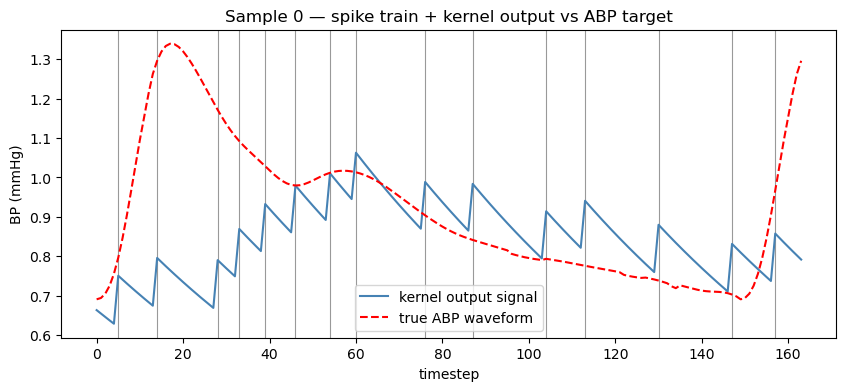

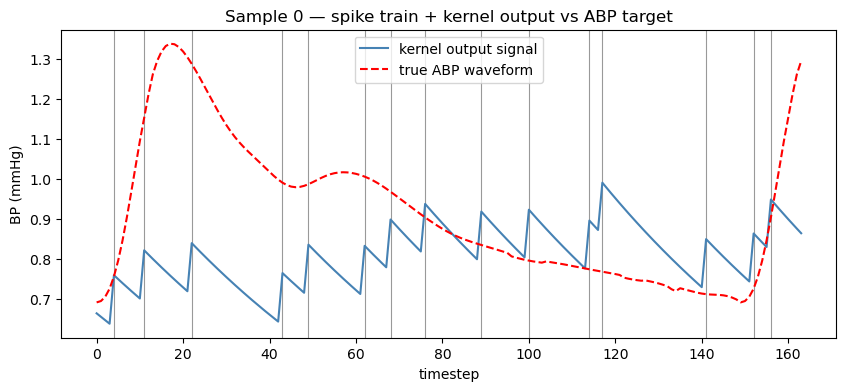

Generalization Error SBP = 37.2441, Generalization Error DBP = 14.1785


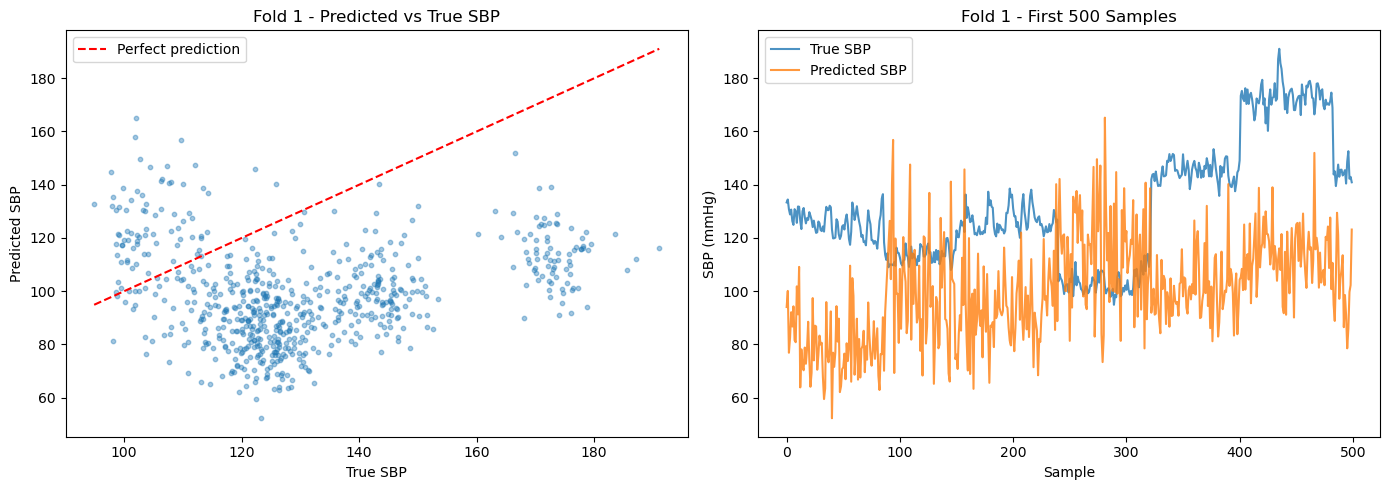

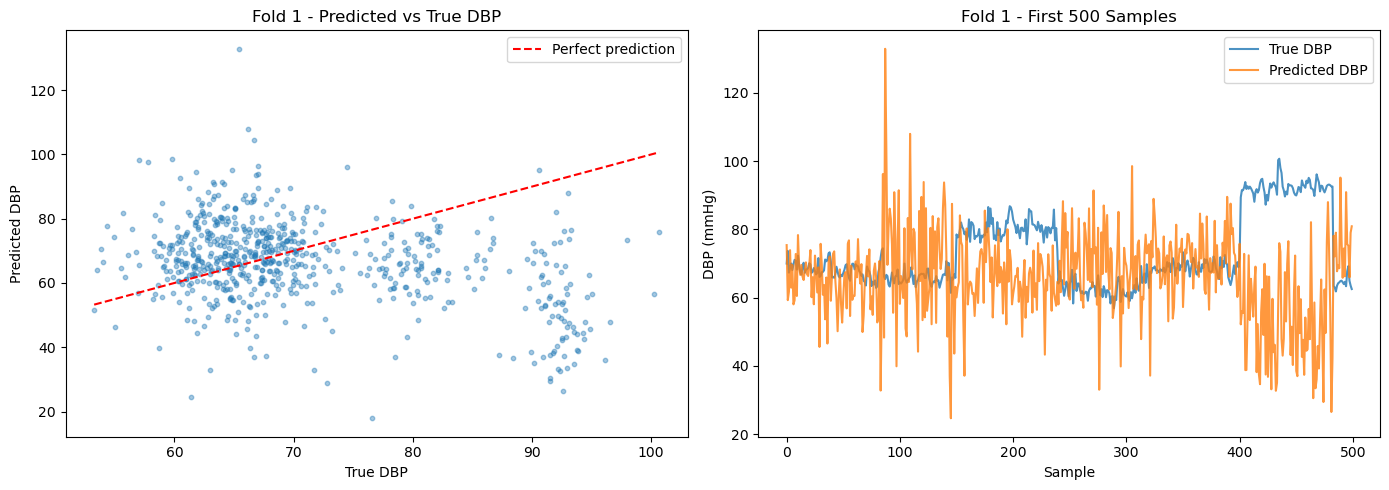


Fold 2/5
Epoch 1 | Train Loss SBP: 0.4324 | Train Loss DBP: 0.5909


KeyboardInterrupt: 

In [868]:
batch_size = 32
num_epochs = 10
num_inputs = len(top_features_SBP)
num_hidden = 32
num_outputs = 1
beta_val = 0.9

cv_mae_sbp = 0.0    # Cross Validation MAE for SBP
cv_mae_dbp = 0.0
cv_total_samples = 0
fold_maes_sbp = []  # To collect per-fold MAE
fold_maes_dbp = []

for fold in range(num_folds):
    print(f"\nFold {fold+1}/{num_folds}")

    all_predictions_sbp = []    # fold plotting the pred vs true values
    all_true_sbp = []
    all_predictions_dbp = []
    all_true_dbp = []

    net_sbp = Net(num_inputs, num_hidden, num_outputs, beta_val, num_steps)
    net_dbp = Net(num_inputs, num_hidden, num_outputs, beta_val, num_steps)

    optimizer_sbp = optim.Adam(net_sbp.parameters(), lr=lr)
    optimizer_dbp = optim.Adam(net_dbp.parameters(), lr=lr)

    test_data = load_data(fold)
    train_data = pd.concat([load_data(i) for i in range(num_folds) if i != fold])

    abp_test = torch.tensor(load_abp(fold), dtype=torch.float32)
    abp_train = torch.cat([torch.tensor(load_abp(i), dtype=torch.float32) for i in range(num_folds) if i != fold], dim=0)

    X_train_sbp = torch.tensor(train_data[top_features_SBP].values, dtype=torch.float32)
    X_train_dbp = torch.tensor(train_data[top_features_DBP].values, dtype=torch.float32)
    X_test_sbp = torch.tensor(test_data[top_features_SBP].values, dtype=torch.float32)
    X_test_dbp = torch.tensor(test_data[top_features_DBP].values, dtype=torch.float32)
    y_train = torch.tensor(train_data.iloc[:, 2:4].values, dtype=torch.float32)
    y_test = torch.tensor(test_data.iloc[:, 2:4].values, dtype=torch.float32)

    # per feature SBP normalization
    X_min_sbp = X_train_sbp.min(dim=0).values
    X_max_sbp = X_train_sbp.max(dim=0).values
    X_train_sbp = (X_train_sbp - X_min_sbp) / (X_max_sbp - X_min_sbp + eps)
    X_test_sbp  = (X_test_sbp - X_min_sbp) / (X_max_sbp - X_min_sbp + eps)

    # per feature DBP normalization
    X_min_dbp = X_train_dbp.min(dim=0).values
    X_max_dbp = X_train_dbp.max(dim=0).values
    X_train_dbp = (X_train_dbp - X_min_dbp) / (X_max_dbp - X_min_dbp + eps)
    X_test_dbp  = (X_test_dbp - X_min_dbp) / (X_max_dbp - X_min_dbp + eps)

    train_loader = DataLoader(
        TensorDataset(X_train_sbp, X_train_dbp, y_train, abp_train),
        batch_size=batch_size, shuffle=True
    )
    test_loader = DataLoader(
        TensorDataset(X_test_sbp, X_test_dbp, y_test, abp_test),
        batch_size=batch_size, shuffle=False
    )

    # Training
    for epoch in range(num_epochs):
        net_sbp.train()
        net_dbp.train()
        num_batches = 0
        total_train_loss_sbp = 0
        total_train_loss_dbp = 0

        for x_sbp, x_dbp, y, abp in train_loader:
            x_sbp = x_sbp.to(device)
            x_dbp = x_dbp.to(device)
            y = y.to(device)
            abp = abp.to(device)

            optimizer_sbp.zero_grad()
            spk_sbp = net_sbp(x_sbp)    # [T, batch, 1]
            sig_sbp = apply_exponential_kernel(spk_sbp, kernel_decay)*SCALING_FACTOR  # [T, batch, 1]
            #sig_sbp = torch.clamp(sig_sbp, min=0.7, max=2.0)
            target_sbp = (abp / 100.0).permute(1, 0).unsqueeze(-1)   # [164, batch, 1]
            #sig_sbp_s = smooth(sig_sbp, window=3)
            #loss_sbp = torch.mean(torch.abs(sig_sbp_s - target_sbp))
            loss_sbp = torch.mean(torch.abs(sig_sbp - target_sbp))
            loss_sbp.backward()
            torch.nn.utils.clip_grad_norm_(net_sbp.parameters(), max_norm=1.0)
            optimizer_sbp.step()

            optimizer_dbp.zero_grad()
            spk_dbp = net_dbp(x_dbp)
            sig_dbp = apply_exponential_kernel(spk_dbp, kernel_decay)*SCALING_FACTOR
            #sig_dbp = torch.clamp(sig_dbp, min=0.45, max=2.0)
            target_dbp = (abp / 100.0).permute(1, 0).unsqueeze(-1)   # [164, batch, 1]
            #sig_dbp_s = smooth(sig_dbp, window=3)
            #loss_dbp = torch.mean(torch.abs(sig_dbp_s - target_dbp))
            loss_dbp = torch.mean(torch.abs(sig_dbp - target_dbp))
            loss_dbp.backward()
            torch.nn.utils.clip_grad_norm_(net_dbp.parameters(), max_norm=1.0)
            optimizer_dbp.step()

            '''
            if num_batches == 0 and epoch == 0:
                plot_signal(sig_sbp_s, spk_sbp, abp, sample_idx=0)
                plot_signal(sig_dbp_s, spk_dbp, abp, sample_idx=0)
            '''

            total_train_loss_sbp += loss_sbp.item()
            total_train_loss_dbp += loss_dbp.item()
            num_batches += 1

        print(f"Epoch {epoch+1} | Train Loss SBP: {total_train_loss_sbp / num_batches:.4f} "
              f"| Train Loss DBP: {total_train_loss_dbp / num_batches:.4f}")

    # Evaluation
    net_sbp.eval()
    net_dbp.eval()
    total_mae_sbp = 0
    total_mae_dbp = 0
    total_samples = 0
    true_sbp_list = []
    pred_sbp_list = []
    true_dbp_list = []
    pred_dbp_list = []

    with torch.no_grad():
        for x_sbp, x_dbp, y, abp in test_loader:
            x_sbp = x_sbp.to(device)
            x_dbp = x_dbp.to(device)
            y = y.to(device)
            abp = abp.to(device)

            spk_sbp = net_sbp(x_sbp)
            spk_dbp = net_dbp(x_dbp)

            sig_sbp = apply_exponential_kernel(spk_sbp, kernel_decay)*SCALING_FACTOR  # [T, batch, 1]
            #sig_sbp = torch.clamp(sig_sbp, min=0.7, max=2.0)
            sig_dbp = apply_exponential_kernel(spk_dbp, kernel_decay)*SCALING_FACTOR
            #sig_dbp = torch.clamp(sig_dbp, min=0.45, max=2.0)

            #pred_sbp = sig_sbp[82:].max(dim=0).values[:,0] * 100.0
            #pred_dbp = sig_dbp[82:].min(dim=0).values[:,0] * 100.0

            pred_sbp = torch.quantile(sig_sbp[82:,:,0], 0.95, dim=0) * 100.0
            pred_dbp = torch.quantile(sig_dbp[82:,:,0], 0.05, dim=0) * 100.0

            if total_samples == 0:
                plot_signal(sig_sbp, spk_sbp, abp, sample_idx=0)
                plot_signal(sig_dbp, spk_dbp, abp, sample_idx=0)

            mae_sbp = torch.abs(pred_sbp - y[:, 0]).sum().item()
            mae_dbp = torch.abs(pred_dbp - y[:, 1]).sum().item()

            true_sbp_list.extend(y[:, 0].cpu().numpy())
            pred_sbp_list.extend(pred_sbp.cpu().numpy())
            true_dbp_list.extend(y[:, 1].cpu().numpy())
            pred_dbp_list.extend(pred_dbp.cpu().numpy())

            total_mae_sbp += mae_sbp
            total_mae_dbp += mae_dbp
            total_samples += y.shape[0]

    fold_mae_sbp = total_mae_sbp / total_samples
    fold_mae_dbp = total_mae_dbp / total_samples

    fold_maes_sbp.append(fold_mae_sbp)
    fold_maes_dbp.append(fold_mae_dbp)

    cv_mae_sbp += total_mae_sbp
    cv_mae_dbp += total_mae_dbp
    cv_total_samples += total_samples

    print(f"Generalization Error SBP = {fold_mae_sbp:.4f}, Generalization Error DBP = {fold_mae_dbp:.4f}")
    plot_predictions(np.array(true_sbp_list), np.array(pred_sbp_list), "SBP", fold, 500)
    plot_predictions(np.array(true_dbp_list), np.array(pred_dbp_list), "DBP", fold, 500)

print(f"Final CV MAE's: \nSBP: {cv_mae_sbp / cv_total_samples:.4f} ± {np.std(fold_maes_sbp):.4f}\nDBP: {cv_mae_dbp / cv_total_samples:.4f} ± {np.std(fold_maes_dbp):.4f}")